# 07 — Dimensionality Reduction

[Previous](./06_Feature_Selection.ipynb) | [Repository guide](../README.md) | [Next](./08_Outlier_Handling.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** test whether many encoded features can be compressed into fewer numerical components without losing too much predictive performance.

`solution.csv` is never read. Every reducer is fitted inside its validation fold.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


In [1]:
# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_backend
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
solution.csv: intentionally not loaded


## 1. What is dimensionality reduction?

After one-hot encoding and feature engineering, one row becomes many model inputs. A **dimension** is one such input.

- **Feature selection** keeps named inputs and removes others.
- **Dimensionality reduction** mixes inputs into new summary columns called **components**.

PCA might create a component like `0.40 × pressure − 0.31 × keeper_form + ...`. It can compress information, but “PC1” is harder to explain than `pressure_index`.

**Explained variance** is the share of input variation retained. High explained variance does not guarantee high target-prediction quality because PCA does not look at the target.


## 2. Methods to compare

| Method | Beginner meaning | Main trade-off |
|---|---|---|
| No reduction | Send all named encoded features to the model | Most interpretable; largest input |
| PCA 95% | Keep enough mixed components to preserve 95% of input variation | Automatic size; target-blind |
| PCA 15 | Force all information into 15 mixed components | Compact; may discard useful signal |
| Truncated SVD 15 | Sparse-friendly compression without centering | Efficient; also target-blind |
| LDA 1 | Use labels to find one class-separation direction | Very compact; must fit inside CV |


In [4]:
FEATURE_GROUPS = {
    "Relative ability": ["skill_advantage", "foot_difference", "skill_ratio_share", "skill_proxy"],
    "Match state": [
        "is_close_game", "is_losing", "is_tied", "is_winning", "match_status",
        "home_crowd_aligned", "is_poor_pitch", "final_extra_time",
    ],
    "Pressure components": ["pressure_index", "low_pressure", "late_minute", "extreme_pressure", "is_weak_player"],
    "Problem interactions": [
        "skill_gap_x_low_pressure", "disaster_combo", "pressure_x_weak",
        "pressure_skill", "keeper_pressure", "late_close_game",
    ],
    "Nonlinear and cyclical": [
        "player_form_squared", "keeper_form_squared", "skill_to_keeper_ratio",
        "score_x_minute", "minute_sin", "minute_cos", "humidity_sq_weak",
        "skill_keeper_product", "humidity_minute_interaction",
    ],
    "Composure proxies": ["clutch_boost", "choke_penalty"],
}


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    # Relative-ability hypotheses.
    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    # Match state: whether the kicker's team is leading, tied, or losing.
    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    # Post-competition reconstruction of the problem's pressure idea.
    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    # Interactions: one condition changes the effect of another.
    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    # Generic suggested candidates: useful to test even when the result rejects them.
    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    # Composure is hidden; skill_proxy is a visible, imperfect substitute.
    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result

engineered_columns = []
for group_columns in FEATURE_GROUPS.values():
    engineered_columns.extend(group_columns)
X_original = train.drop(columns=[TARGET] + ID_COLUMNS)
X = add_engineered_features(X_original)
y = train[TARGET].astype(int)
model_columns = X_original.columns.tolist() + engineered_columns


## 3. Leakage-safe comparison

The reducer belongs after preprocessing and before the classifier. During cross-validation, it learns its components only from that fold’s training rows. For LDA, this is essential because LDA sees the target labels.

In [5]:
categorical_columns = X_original.select_dtypes(exclude=np.number).columns.tolist()
numerical_columns = X_original.select_dtypes(include=np.number).columns.tolist() + engineered_columns
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numerical_columns),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_columns),
])

experiments = [
    ("No reduction", "passthrough"),
    ("PCA 95% variance", PCA(n_components=0.95, random_state=RANDOM_STATE)),
    ("PCA 15 components", PCA(n_components=15, random_state=RANDOM_STATE)),
    ("Truncated SVD 15", TruncatedSVD(n_components=15, random_state=RANDOM_STATE)),
    ("LDA 1 component", LinearDiscriminantAnalysis(n_components=1)),
]


In [6]:
rows = []
fitted_pipelines = {}

for name, reducer in experiments:
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("reducer", reducer),
        ("model", LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)),
    ])

    with parallel_backend("threading"):
        class_probabilities = cross_val_predict(
            pipeline, X[model_columns], y, cv=cv,
            method="predict_proba", n_jobs=-1,
        )
        # Column 0 = missed; column 1 = scored. Keep the scoring probability.
        probabilities = class_probabilities[:, 1]

    predictions = (probabilities >= 0.5).astype(int)
    fold_f1 = []
    # Score each validation fold separately to check consistency.
    for unused_training_rows, validation_rows in cv.split(X, y):
        fold_score = f1_score(y.iloc[validation_rows], predictions[validation_rows])
        fold_f1.append(fold_score)
    pipeline.fit(X[model_columns], y)
    transformed_count = pipeline[:-1].transform(X[model_columns].iloc[:2]).shape[1]
    fitted_pipelines[name] = pipeline

    rows.append({
        "method": name,
        "components": transformed_count,
        "f1": f1_score(y, predictions),
        "f1_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, probabilities),
    })

results = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(results)


,method,components,f1,f1_std,precision,recall,accuracy,roc_auc
0,No reduction,66,0.8847,0.0061,0.8916,0.8779,0.8970,0.9625
1,LDA 1 component,1,0.8808,0.0046,0.8883,0.8733,0.8936,0.9615
2,PCA 95% variance,30,0.8732,0.0045,0.8838,0.8628,0.8872,0.9555
3,Truncated SVD 15,15,0.8415,0.0042,0.8566,0.8269,0.8598,0.9381
4,PCA 15 components,15,0.8408,0.0045,0.8555,0.8267,0.8591,0.9376


### Concrete dataset example: a two-component PCA picture

For visualization only, we fit a two-component PCA to all training inputs and color by the known training target. This picture helps explain compression; it is not used for the reported validation scores. The scored methods above still fit PCA separately inside every fold.


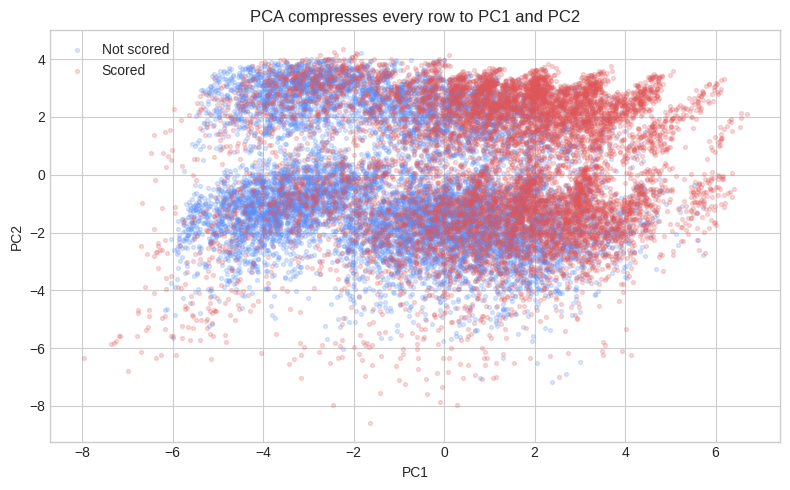

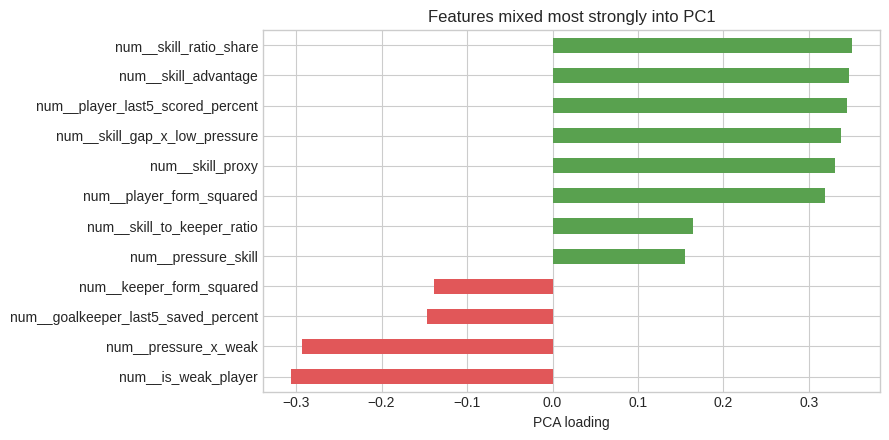

PC1 + PC2 preserve 24.9% of total input variation.


In [7]:
visual_preprocessor = fitted_pipelines["No reduction"].named_steps["preprocessor"]
visual_inputs = visual_preprocessor.transform(X[model_columns])
visual_pca = PCA(n_components=2, random_state=RANDOM_STATE)
visual_coordinates = visual_pca.fit_transform(visual_inputs)

fig, ax = plt.subplots(figsize=(8, 5))
for label, color, name in [(0, "#5b8ff9", "Not scored"), (1, "#e15759", "Scored")]:
    mask = y.to_numpy() == label
    ax.scatter(visual_coordinates[mask, 0], visual_coordinates[mask, 1], s=8, alpha=0.22, color=color, label=name)
ax.set(title="PCA compresses every row to PC1 and PC2", xlabel="PC1", ylabel="PC2")
ax.legend()
plt.tight_layout()
plt.show()

visual_names = visual_preprocessor.get_feature_names_out()
pc1_loadings = pd.Series(visual_pca.components_[0], index=visual_names)
top_pc1 = pc1_loadings.loc[pc1_loadings.abs().nlargest(12).index].sort_values()
ax = top_pc1.plot.barh(
    figsize=(9, 4.5), color=np.where(top_pc1 >= 0, "#59a14f", "#e15759"),
    title="Features mixed most strongly into PC1",
)
ax.set(xlabel="PCA loading", ylabel="")
plt.tight_layout()
plt.show()
print(f"PC1 + PC2 preserve {visual_pca.explained_variance_ratio_.sum():.1%} of total input variation.")


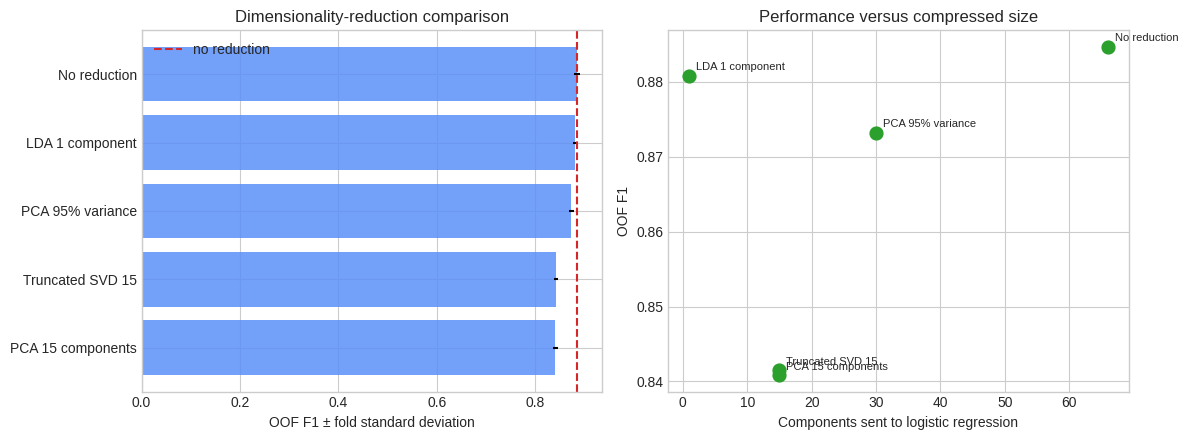

In [8]:
reference = results.loc[results["method"].eq("No reduction")].iloc[0]
ordered = results.sort_values("f1")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(ordered["method"], ordered["f1"], xerr=ordered["f1_std"], color="#5b8ff9", alpha=.85)
axes[0].axvline(reference["f1"], color="#d62728", linestyle="--", label="no reduction")
axes[0].set(title="Dimensionality-reduction comparison", xlabel="OOF F1 ± fold standard deviation", ylabel="")
axes[0].legend()

axes[1].scatter(results["components"], results["f1"], s=85, color="#2ca02c")
for _, row in results.iterrows():
    axes[1].annotate(row["method"], (row["components"], row["f1"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
axes[1].set(title="Performance versus compressed size", xlabel="Components sent to logistic regression", ylabel="OOF F1")
plt.tight_layout()
plt.show()


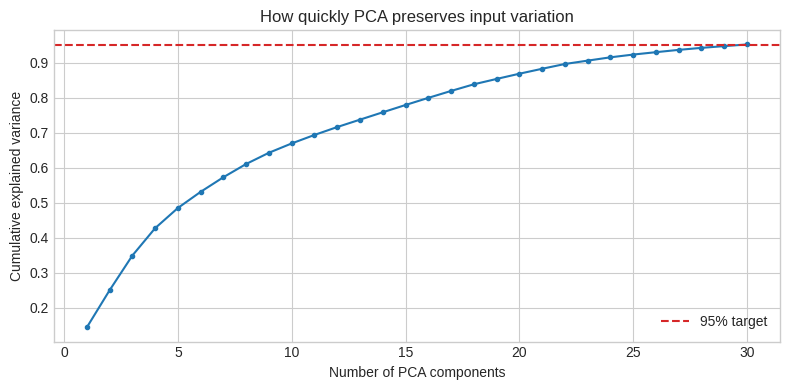

PCA needs 30 components to preserve at least 95% of input variation.


In [9]:
pca_95 = fitted_pipelines["PCA 95% variance"].named_steps["reducer"]
cumulative = np.cumsum(pca_95.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(cumulative) + 1), cumulative, marker="o", markersize=3)
ax.axhline(0.95, color="#d62728", linestyle="--", label="95% target")
ax.set(title="How quickly PCA preserves input variation", xlabel="Number of PCA components", ylabel="Cumulative explained variance")
ax.legend()
plt.tight_layout()
plt.show()
print(f"PCA needs {len(cumulative)} components to preserve at least 95% of input variation.")


## 4. How the decision is made

A reducer must offer either better F1 or a meaningful size saving with an acceptable loss. We compare both axes: OOF F1 and the number of components sent to logistic regression.

Even when a one-component LDA is close, named features remain preferable for a beginner solution unless storage or speed is a real constraint.


In [10]:
best_reduced = results.loc[results["method"].ne("No reduction")].iloc[0]
gain = best_reduced["f1"] - reference["f1"]
near_reference = results.loc[
    results["method"].ne("No reduction") &
    (results["f1"] >= reference["f1"] - reference["f1_std"])
].sort_values(["components", "f1"], ascending=[True, False])

print(f"No-reduction reference: F1 {reference['f1']:.4f} with {int(reference['components'])} encoded features")
print(f"Best reduced method: {best_reduced['method']} | F1 {best_reduced['f1']:.4f} | change {gain:+.4f}")
if gain >= reference["f1_std"]:
    print("Decision: keep the best reduced method; its gain is larger than ordinary fold variation.")
elif not near_reference.empty:
    compact = near_reference.iloc[0]
    print(f"Compact near-reference option: {compact['method']} with {int(compact['components'])} components.")
    print("Decision: keep named features for the final model; use the compact option only when size matters more than interpretability.")
else:
    print("Decision: keep named features; every reduction loses more than ordinary fold variation.")


No-reduction reference: F1 0.8847 with 66 encoded features
Best reduced method: LDA 1 component | F1 0.8808 | change -0.0039
Compact near-reference option: LDA 1 component with 1 components.
Decision: keep named features for the final model; use the compact option only when size matters more than interpretability.


## Other alternatives

- **Kernel PCA:** captures curved relationships; slower and harder to tune.
- **UMAP:** creates compact nonlinear embeddings; useful for visualization, but stochastic and needs an extra package.
- **t-SNE:** excellent for two-dimensional visualization; not designed as a stable train/test preprocessing step.
- **Autoencoder:** a neural network trained to reconstruct its inputs through a small hidden layer; flexible but much more complex.
- **Feature selection:** keeps original feature names instead of mixing them into components. Notebook 06 showed that L1 selection is a better fit when interpretability matters.

In [11]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)
output_path = results_dir / "07_dimensionality_reduction.csv"
results.to_csv(output_path, index=False)
print(f"Saved: {output_path}")


Saved: /kaggle/working/07_dimensionality_reduction.csv


## Why the dimensionality-reduction decision is justified

**Technical evidence:** the score/count chart shows the exact compression trade-off, the PCA curve shows how many components retain 95% of input variation, and every scored reducer is fitted inside its fold.

**Theoretical reason:** PCA preserves input variance rather than target signal and replaces meaningful names with mixtures. We keep named features when compression does not improve F1; LDA remains a valid compact alternative when size matters more than interpretability.
